## `Task` Select best features from from Wine Quality dataset.

* Data Link : https://www.kaggle.com/datasets/rajyellow46/wine-quality

* Drive link : https://docs.google.com/spreadsheets/d/e/2PACX-1vQDVwxneOKOaJL13QMhkAhYrgWlH1tICY7RacUnj_lL8m9uUWaaUf3p7bScNyh_D2Rvt7nc1q11adSy/pub?gid=647503637&single=true&output=csv

Note : Follow approach from Feature Selection Session - 2

# Wrapper Methods For Feature Selection

1) **Exhaustive Feature Selection Method**
2) **Forward Selection Method**
3) **Backward Elimination Method** and
4) **Recursive Feature Eliminination Method**

**Here, in this session, we will learn first three methods**

# 1) `Exhaustive Feature Selection Method`

We will learn in **`Wine Quality Dataset`**

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.float_format', '{:.4f}'.format)
np.set_printoptions(suppress = True, precision=4)

In [2]:
# Read dataset

df = pd.read_csv(r"00 wine_quality_dataset.csv")

df.sample(5)

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
5748,red,9.3000,0.4300,0.4400,1.9000,0.0850,9.0000,22.0000,0.9971,3.2800,0.5500,9.5000,5
2925,white,7.7000,0.2500,0.3000,7.8000,0.0380,67.0000,196.0000,0.9956,3.1000,0.5000,10.1000,5
2982,white,7.0000,0.2000,0.3100,8.0000,0.0500,29.0000,213.0000,0.9960,3.2800,0.5700,10.4000,6
4238,white,6.4000,0.2900,0.1800,15.0000,0.0400,21.0000,116.0000,0.9974,3.1400,0.5000,9.2000,5
6092,red,7.0000,0.7450,0.1200,1.8000,0.1140,15.0000,64.0000,0.9959,3.2200,0.5900,9.5000,6


In [3]:
# Checking missing values if any

df.isnull().sum()

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

In [4]:
# Dropping missing values

df.dropna(axis = 'index', inplace = True)

In [5]:
x = df.drop(columns = ['quality'])
y = df.drop(columns = x)

x.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,white,7.0000,0.2700,0.3600,20.7000,0.0450,45.0000,170.0000,1.0010,3.0000,0.4500,8.8000
1,white,6.3000,0.3000,0.3400,1.6000,0.0490,14.0000,132.0000,0.9940,3.3000,0.4900,9.5000
2,white,8.1000,0.2800,0.4000,6.9000,0.0500,30.0000,97.0000,0.9951,3.2600,0.4400,10.1000
3,white,7.2000,0.2300,0.3200,8.5000,0.0580,47.0000,186.0000,0.9956,3.1900,0.4000,9.9000
4,white,7.2000,0.2300,0.3200,8.5000,0.0580,47.0000,186.0000,0.9956,3.1900,0.4000,9.9000


In [6]:
y.head()

,quality
0,6
1,6
2,6
3,6
4,6


In [7]:
# Train test split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(f'''x_train shape: {x_train.shape}
y_train shape: {y_train.shape}
x_test shape: {x_test.shape}
y_test shape: {y_test.shape}''')

x_train shape: (5170, 12)
y_train shape: (5170, 1)
x_test shape: (1293, 12)
y_test shape: (1293, 1)


In [8]:
# Encoding feature named 'type' --> OneHotEncoder

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop = 'first', sparse_output = False)

# x_train['type'] = ... is applicable bcz there are only two categories here.
# For more than two categories, we had to store new columns in seperate variable.
# drop original 'type' from x_train and x_test and then concenate the new columns in
# x_train and x_test
# Else, for more than 2 categories, we have to use ColumnTransformer. This is simpler.
x_train['type'] = ohe.fit_transform(x_train[['type']])
x_test['type'] = ohe.transform(x_test[['type']])

In [9]:
x_train

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
1795,1.0000,6.7000,0.3700,0.4100,6.3000,0.0610,22.0000,149.0000,0.9953,3.1600,0.4700,9.6000
5101,0.0000,7.0000,0.4200,0.3500,1.6000,0.0880,16.0000,39.0000,0.9961,3.3400,0.5500,9.2000
4580,1.0000,5.7000,0.2000,0.2400,13.8000,0.0470,44.0000,112.0000,0.9984,2.9700,0.6600,8.8000
1767,1.0000,7.4000,0.3200,0.2200,1.7000,0.0510,50.0000,179.0000,0.9955,3.2800,0.6900,8.9000
2920,1.0000,7.4000,0.2800,0.4000,11.9000,0.0320,13.0000,92.0000,0.9963,3.0100,0.4600,10.8000
...,...,...,...,...,...,...,...,...,...,...,...,...
927,1.0000,6.7000,0.2500,0.3300,2.9000,0.0570,52.0000,173.0000,0.9934,3.0200,0.4800,9.5000
5220,0.0000,7.8000,0.6200,0.0500,2.3000,0.0790,6.0000,18.0000,0.9973,3.2900,0.6300,9.3000
4006,1.0000,5.4000,0.1500,0.3200,2.5000,0.0370,10.0000,51.0000,0.9888,3.0400,0.5800,12.6000
243,1.0000,6.8000,0.2400,0.3400,2.7000,0.0470,64.5000,218.5000,0.9934,3.3000,0.5800,9.7000


In [42]:
# Scaling the data

from sklearn.preprocessing import StandardScaler

ss = StandardScaler().set_output(transform = 'pandas')

x_train = ss.fit_transform(x_train)
x_test = ss.fit_transform(x_test)

In [44]:
x_train

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
1795,0.5709,-0.3927,0.1915,0.6319,0.1771,0.1418,-0.4800,0.5873,0.1997,-0.3655,-0.4102,-0.7475
5101,-1.7515,-0.1621,0.4965,0.2168,-0.8073,0.9023,-0.8192,-1.3664,0.4657,0.7532,0.1265,-1.0829
4580,0.5709,-1.1616,-0.8455,-0.5442,1.7480,-0.2526,0.7636,-0.0698,1.2204,-1.5463,0.8643,-1.4184
1767,0.5709,0.1455,-0.1135,-0.6825,-0.7864,-0.1399,1.1028,1.1202,0.2662,0.3803,1.0655,-1.3346
2920,0.5709,0.1455,-0.3575,0.5628,1.3500,-0.6751,-0.9888,-0.4251,0.5288,-1.2977,-0.4772,0.2590
...,...,...,...,...,...,...,...,...,...,...,...,...
927,0.5709,-0.3927,-0.5405,0.0785,-0.5351,0.0291,1.2158,1.0136,-0.4320,-1.2355,-0.3431,-0.8313
5220,-1.7515,0.4531,1.7166,-1.8586,-0.6607,0.6488,-1.3845,-1.7394,0.8813,0.4425,0.6631,-0.9991
4006,0.5709,-1.3923,-1.1505,0.0093,-0.6188,-0.5342,-1.1584,-1.1533,-1.9680,-1.1112,0.3277,1.7686
243,0.5709,-0.3158,-0.6015,0.1477,-0.5769,-0.2526,1.9224,1.8218,-0.4320,0.5046,0.3277,-0.6636


# Decision Tree

In [45]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

lr = DecisionTreeClassifier(random_state = 1)

model = lr.fit(x_train, y_train)

In [46]:
pd.DataFrame(
    model.feature_importances_, 
    columns = ['Importance'], 
    index = x_train.columns
    ).rename_axis('Feature').sort_values('Importance', ascending = False)

,Importance
Feature,
alcohol,0.1430
volatile acidity,0.1104
pH,0.0896
free sulfur dioxide,0.0888
residual sugar,0.0874
total sulfur dioxide,0.0841
density,0.0823
chlorides,0.0818
sulphates,0.0792


In [47]:
y_pred = lr.predict(x_test)

from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_pred)

print(f"Accuracy on all Features: {acc}")

Accuracy on all Features: 0.5986078886310905


In [ ]:
# Applying cross_validation

cross_val_score(
    estimator = DecisionTreeClassifier(),
    X = x_train, 
    y = y_train, 
    cv = 5
    ).mean()

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


np.float64(0.5851063829787234)

# 1) Exhaustive Feature Elimination

In [49]:
from mlxtend.feature_selection import ExhaustiveFeatureSelector

efs = ExhaustiveFeatureSelector(
    estimator = DecisionTreeClassifier(random_state = 1),
    min_features = 1,
    max_features = 12,    # We have total 13 Features
    scoring = 'accuracy',
    cv = 4,
    n_jobs = -1,
)

selector = efs.fit(x_train, y_train)

Features: 4095/4095

In [50]:
print(selector.best_score_)
print(selector.best_feature_names_)

0.583173805607235
('volatile acidity', 'residual sugar', 'chlorides', 'total sulfur dioxide', 'pH', 'sulphates', 'alcohol')


In [51]:
selector.get_metric_dict()

{0: {'feature_idx': (0,),
  'cv_scores': array([0.4401, 0.4455, 0.4427, 0.4497]),
  'avg_score': np.float64(0.4444880925871386),
  'feature_names': ('type',),
  'ci_bound': np.float64(0.005709242115864442),
  'std_dev': np.float64(0.003561639810157451),
  'std_err': np.float64(0.002056313703150892)},
 1: {'feature_idx': (1,),
  'cv_scores': array([0.4385, 0.4424, 0.4319, 0.4211]),
  'avg_score': np.float64(0.4334595787270825),
  'feature_names': ('fixed acidity',),
  'ci_bound': np.float64(0.012962589884506026),
  'std_dev': np.float64(0.008086550760759002),
  'std_err': np.float64(0.004668772258539782)},
 2: {'feature_idx': (2,),
  'cv_scores': array([0.4671, 0.4594, 0.4582, 0.4512]),
  'avg_score': np.float64(0.45899254499699504),
  'feature_names': ('volatile acidity',),
  'ci_bound': np.float64(0.009037361013830346),
  'std_dev': np.float64(0.005637845463968289),
  'std_err': np.float64(0.0032550115962716023)},
 3: {'feature_idx': (3,),
  'cv_scores': array([0.4501, 0.447 , 0.4373,

In [52]:
efs_result = pd.DataFrame(
    selector.get_metric_dict()
    ).T.sort_values(by = 'avg_score', ascending = False)

efs_result

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
3250,"(2, 4, 5, 7, 9, 10, 11)","[0.5931941221964424, 0.5645784996133024, 0.589...",0.5832,"(volatile acidity, residual sugar, chlorides, ...",0.0177,0.0110,0.0064
4090,"(0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11)","[0.6009280742459396, 0.5568445475638051, 0.582...",0.5797,"(type, fixed acidity, volatile acidity, residu...",0.0251,0.0156,0.0090
2170,"(1, 2, 7, 8, 10, 11)","[0.5815931941221965, 0.5854601701469451, 0.590...",0.5793,"(fixed acidity, volatile acidity, total sulfur...",0.0189,0.0118,0.0068
3689,"(1, 2, 4, 5, 6, 7, 8, 11)","[0.5908739365815932, 0.5576179427687549, 0.576...",0.5780,"(fixed acidity, volatile acidity, residual sug...",0.0206,0.0128,0.0074
4045,"(0, 1, 2, 4, 5, 6, 7, 8, 9, 11)","[0.5877803557617943, 0.5506573859242073, 0.596...",0.5778,"(type, fixed acidity, volatile acidity, residu...",0.0278,0.0173,0.0100
...,...,...,...,...,...,...,...
20,"(0, 9)","[0.4323279195668987, 0.4091260634184068, 0.442...",0.4310,"(type, pH)",0.0211,0.0132,0.0076
47,"(3, 9)","[0.4508894044856922, 0.41608662026295434, 0.42...",0.4298,"(citric acid, pH)",0.0210,0.0131,0.0076
31,"(1, 10)","[0.4276875483372003, 0.44470224284609433, 0.42...",0.4286,"(fixed acidity, sulphates)",0.0155,0.0097,0.0056
27,"(1, 6)","[0.42846094354215003, 0.43928847641144625, 0.4...",0.4282,"(fixed acidity, free sulfur dioxide)",0.0109,0.0068,0.0039


In [53]:
# Training the model on best selected features
x_train_trans = efs.fit_transform(x_train, y_train)
x_test_trans = efs.transform(x_test)

Features: 4095/4095

In [54]:
x_train_trans = pd.DataFrame(x_train_trans, columns = efs.best_feature_names_)

x_train_trans.head()

,volatile acidity,residual sugar,chlorides,total sulfur dioxide,pH,sulphates,alcohol
0,0.1915,0.1771,0.1418,0.5873,-0.3655,-0.4102,-0.7475
1,0.4965,-0.8073,0.9023,-1.3664,0.7532,0.1265,-1.0829
2,-0.8455,1.7480,-0.2526,-0.0698,-1.5463,0.8643,-1.4184
3,-0.1135,-0.7864,-0.1399,1.1202,0.3803,1.0655,-1.3346
4,-0.3575,1.3500,-0.6751,-0.4251,-1.2977,-0.4772,0.2590


In [55]:
cross_val_score(
    estimator = DecisionTreeClassifier(),
    X = x_train_trans,
    y = y_train,
    n_jobs = -1, 
    cv = 5
    ).mean()

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


np.float64(0.5750483558994197)

# Conclusion of Exhaustive Feature Selection
See, earlier with all `13 columns` we got `0.5798` accuracy and now with just `7 columns`, we are getting `0.58` accuracy.

`Let's plot and see the accuracy of top 10 models

In [56]:
top_10_models_features = [str(features) for features in efs_result.head(10)['feature_names']]
top_10_avg_accuracy = efs_result.head(10)['avg_score']


print(f'''Features of top 10 models
{top_10_models_features}
========================
Average score of top 10 models
{top_10_avg_accuracy}''')

Features of top 10 models
["('volatile acidity', 'residual sugar', 'chlorides', 'total sulfur dioxide', 'pH', 'sulphates', 'alcohol')", "('type', 'fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol')", "('fixed acidity', 'volatile acidity', 'total sulfur dioxide', 'density', 'sulphates', 'alcohol')", "('fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'alcohol')", "('type', 'fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'alcohol')", "('type', 'volatile acidity', 'citric acid', 'residual sugar', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'sulphates', 'alcohol')", "('type', 'fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol')", "('fixed

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, "('volatile acidity', 'residual sugar', 'chlorides', 'total sulfur dioxide', 'pH', 'sulphates', 'alcohol')"),
  Text(1, 0, "('type', 'fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol')"),
  Text(2, 0, "('fixed acidity', 'volatile acidity', 'total sulfur dioxide', 'density', 'sulphates', 'alcohol')"),
  Text(3, 0, "('fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'alcohol')"),
  Text(4, 0, "('type', 'fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'alcohol')"),
  Text(5, 0, "('type', 'volatile acidity', 'citric acid', 'residual sugar', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'sulphates', 'alcohol')"),
  Text(6, 0, "('type', 'fixed acidity', 'volatile acidity', 're

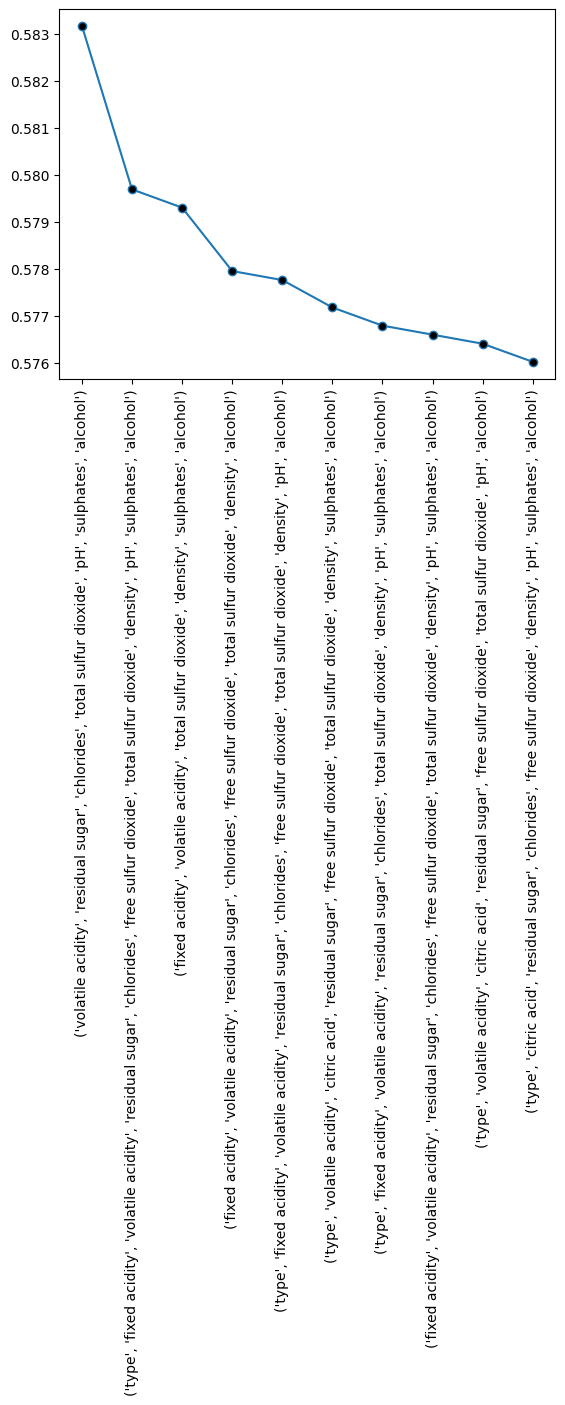

In [57]:
# Plotting
import matplotlib.pyplot as plt

plt.plot(
    top_10_models_features, 
    top_10_avg_accuracy, 
    marker = 'o', 
    markerfacecolor = 'black')

plt.xticks(rotation = 90)

# Sequential Backward Elimination

In [111]:
from mlxtend.feature_selection import SequentialFeatureSelector

sfs = SequentialFeatureSelector(
    estimator = DecisionTreeClassifier(),
    k_features = 7,
    forward = False,
    floating = False,
    verbose = True,
    scoring = 'accuracy',
    cv = 5,
    n_jobs = -1
)

x_train_trans = sfs.fit_transform(x_train, y_train)
x_test_trans = sfs.transform(x_test)

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 out of  12 | elapsed:   13.6s remaining:    2.6s
[Parallel(n_jobs=-1)]: Done  12 out of  12 | elapsed:   13.6s finished
Features: 11/7[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   8 out of  11 | elapsed:    0.3s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done  11 out of  11 | elapsed:    0.4s finished
Features: 10/7[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   6 out of  10 | elapsed:    0.2s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:    0.3s finished
Features: 9/7[Parallel(n_jobs=-1)]: Using backend LokyBackend wi

In [112]:
sfs.k_feature_names_

# See we are getting all the features we got in EFS. Only one feature is not present

('volatile acidity',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'density',
 'sulphates',
 'alcohol')

In [113]:
sfs_result = pd.DataFrame(
    
    sfs.get_metric_dict()
    ).T.sort_values(by = 'avg_score', ascending = False)

sfs_result

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
11,"(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","[0.6131528046421664, 0.5686653771760155, 0.566...",0.5867,"(fixed acidity, volatile acidity, citric acid,...",0.0249,0.0194,0.0097
9,"(2, 3, 4, 5, 6, 7, 8, 10, 11)","[0.5947775628626693, 0.5793036750483559, 0.599...",0.5859,"(volatile acidity, citric acid, residual sugar...",0.0128,0.0100,0.0050
12,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","[0.59284332688588, 0.5696324951644101, 0.56963...",0.5855,"(type, fixed acidity, volatile acidity, citric...",0.0210,0.0163,0.0082
8,"(2, 4, 5, 6, 7, 8, 10, 11)","[0.6054158607350096, 0.5764023210831721, 0.571...",0.5843,"(volatile acidity, residual sugar, chlorides, ...",0.0217,0.0168,0.0084
10,"(2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","[0.597678916827853, 0.5812379110251451, 0.5735...",0.5820,"(volatile acidity, citric acid, residual sugar...",0.0118,0.0091,0.0046
7,"(2, 4, 5, 6, 8, 10, 11)","[0.5773694390715667, 0.5764023210831721, 0.588...",0.5787,"(volatile acidity, residual sugar, chlorides, ...",0.0115,0.0090,0.0045


In [114]:
sfs_result

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
11,"(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","[0.6131528046421664, 0.5686653771760155, 0.566...",0.5867,"(fixed acidity, volatile acidity, citric acid,...",0.0249,0.0194,0.0097
9,"(2, 3, 4, 5, 6, 7, 8, 10, 11)","[0.5947775628626693, 0.5793036750483559, 0.599...",0.5859,"(volatile acidity, citric acid, residual sugar...",0.0128,0.0100,0.0050
12,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","[0.59284332688588, 0.5696324951644101, 0.56963...",0.5855,"(type, fixed acidity, volatile acidity, citric...",0.0210,0.0163,0.0082
8,"(2, 4, 5, 6, 7, 8, 10, 11)","[0.6054158607350096, 0.5764023210831721, 0.571...",0.5843,"(volatile acidity, residual sugar, chlorides, ...",0.0217,0.0168,0.0084
10,"(2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","[0.597678916827853, 0.5812379110251451, 0.5735...",0.5820,"(volatile acidity, citric acid, residual sugar...",0.0118,0.0091,0.0046
7,"(2, 4, 5, 6, 8, 10, 11)","[0.5773694390715667, 0.5764023210831721, 0.588...",0.5787,"(volatile acidity, residual sugar, chlorides, ...",0.0115,0.0090,0.0045


In [115]:
sfs_result[['feature_names', 'avg_score']].iloc[0]


# Technique          No_of_features          Avg_score
# SFS(Backward)           6                       0.5892    (Better than EFS)
# EFS                            7                      0.5832      

feature_names    (fixed acidity, volatile acidity, citric acid,...
avg_score                                                   0.5867
Name: 11, dtype: object

In [116]:
x_train_trans = pd.DataFrame(x_train_trans, columns = sfs.k_feature_names_)

x_train_trans.head(5)

,volatile acidity,residual sugar,chlorides,free sulfur dioxide,density,sulphates,alcohol
0,0.1915,0.1771,0.1418,-0.4800,0.1997,-0.4102,-0.7475
1,0.4965,-0.8073,0.9023,-0.8192,0.4657,0.1265,-1.0829
2,-0.8455,1.7480,-0.2526,0.7636,1.2204,0.8643,-1.4184
3,-0.1135,-0.7864,-0.1399,1.1028,0.2662,1.0655,-1.3346
4,-0.3575,1.3500,-0.6751,-0.9888,0.5288,-0.4772,0.2590


In [117]:
# CV on best 6 features

cross_val_score(
    estimator = DecisionTreeClassifier(),
    X = x_train_trans,
    y = y_train,
    cv = 5,
    scoring = 'accuracy',
    n_jobs = -1
).mean()

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


np.float64(0.5823984526112185)

`EFS`--> 7 Features--> Accuracy (0.5832)    <br>
`SFS`--> 7 Features--> Accuracy (0.5823)

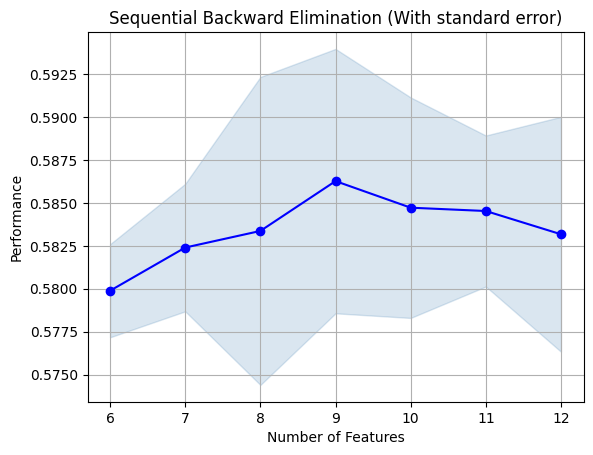

In [100]:
from mlxtend.plotting import plot_sequential_feature_selection as psfc
import matplotlib.pyplot as plt

fig = psfc(sfs.get_metric_dict(), kind = 'std_err')

plt.title('Sequential Backward Elimination (With standard error)')
plt.grid()

# The shaded area shows standard error. As cv = 5, it would train 5 models and each model
# would have its own error. So shaded area shows range of standard errors.

# Mutual_Info_Classif

In [101]:
from sklearn.feature_selection import mutual_info_classif

# Calculate mutual info
mi = mutual_info_classif(x_train, y_train)

# print mutual info
for i, mutual_info in enumerate(mi):
    print(f"Feature{i}: Mutual Info = {mutual_info}")

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Feature0: Mutual Info = 0.01588834467407496
Feature1: Mutual Info = 0.027652454928159376
Feature2: Mutual Info = 0.06254673341241457
Feature3: Mutual Info = 0.03841662768074228
Feature4: Mutual Info = 0.05799903575101073
Feature5: Mutual Info = 0.07597913679787283
Feature6: Mutual Info = 0.04560912779894588
Feature7: Mutual Info = 0.06802917118868868
Feature8: Mutual Info = 0.1477884295876244
Feature9: Mutual Info = 0.014398558241597748
Feature10: Mutual Info = 0.026814308993709624
Feature11: Mutual Info = 0.1468014883155475


In [104]:
mutual_info_df = pd.DataFrame(
    data = mi, 
    columns = ['Mutual Information'], 
    index= x_train.columns
    ).rename_axis('Feature').sort_values(by = 'Mutual Information', ascending = False)

mutual_info_df

,Mutual Information
Feature,
density,0.1478
alcohol,0.1468
chlorides,0.0760
total sulfur dioxide,0.0680
volatile acidity,0.0625
residual sugar,0.0580
free sulfur dioxide,0.0456
citric acid,0.0384
fixed acidity,0.0277


In [107]:
# We can also use mutual_info_classif with SelectKBest

from sklearn.feature_selection import SelectKBest

skb = SelectKBest(score_func = mutual_info_classif, k = 7).set_output(transform = 'pandas')

x_train_trans = skb.fit_transform(x_train, y_train)

x_train_trans

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,volatile acidity,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,alcohol
1795,0.1915,0.1771,0.1418,-0.4800,0.5873,0.1997,-0.7475
5101,0.4965,-0.8073,0.9023,-0.8192,-1.3664,0.4657,-1.0829
4580,-0.8455,1.7480,-0.2526,0.7636,-0.0698,1.2204,-1.4184
1767,-0.1135,-0.7864,-0.1399,1.1028,1.1202,0.2662,-1.3346
2920,-0.3575,1.3500,-0.6751,-0.9888,-0.4251,0.5288,0.2590
...,...,...,...,...,...,...,...
927,-0.5405,-0.5351,0.0291,1.2158,1.0136,-0.4320,-0.8313
5220,1.7166,-0.6607,0.6488,-1.3845,-1.7394,0.8813,-0.9991
4006,-1.1505,-0.6188,-0.5342,-1.1584,-1.1533,-1.9680,1.7686
243,-0.6015,-0.5769,-0.2526,1.9224,1.8218,-0.4320,-0.6636


In [108]:
# CV on best 6 features

cross_val_score(
    estimator = DecisionTreeClassifier(),
    X = x_train_trans,
    y = y_train,
    cv = 5,
    scoring = 'accuracy',
    n_jobs = -1
).mean()

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


np.float64(0.5688588007736943)

In [110]:
df.shape

(6463, 13)

# Conclusion

| Technique | No. of Features | Average CV Accuracy |
|---|---:|---:|
| Decision Tree – All Features | 13 | 0.5851 |
| Exhaustive Feature Selector | 7 | 0.5750 |
| Sequential Backward Selection | 7 | 0.5823 |
| Mutual Information (SelectKBest) | 7 | 0.5689 |


# Task 55: Complete